# Capital Asset Pricing Model (CAPM) Stock Analysis

This notebook implements the Capital Asset Pricing Model (CAPM) to evaluate risk and return profiles for selected individual stocks (AAPL, MSFT, GOOG, AMZN) relative to the market index (SPY).

## Theoretical Background
The CAPM model describes the relationship between systematic risk and expected return for assets, particularly stocks. The formula is:

$$E(R_i) = R_f + \beta_i (E(R_m) - R_f)$$

Where:
- $E(R_i)$ is the expected return of the asset.
- $R_f$ is the risk-free rate.
- $\beta_i$ is the beta of the asset (measure of systematic risk relative to the market).
- $E(R_m)$ is the expected return of the market index.
- $E(R_m) - R_f$ is the market risk premium.

We also compute key metrics:
- **Alpha ($\alpha$)**: The excess return of the stock relative to the return predicted by CAPM (measure of active return).
- **Sharpe Ratio**: Reward-to-volatility ratio, defined as $(R_i - R_f) / \sigma_i$.
- **Treynor Ratio**: Reward-to-beta ratio, defined as $(R_i - R_f) / \beta_i$.

In [1]:
# Imports Section
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Set plots design
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

## 1. Data Ingestion

We fetch historical adjusted closing prices for our target stocks (Apple, Microsoft, Google, Amazon) and the benchmark index S&P 500 (SPY) over a 5-year period.

In [2]:
# Define tickers and period.
# SPY is the market benchmark; the remaining 54 names span all 11 GICS sectors
# so the CAPM / Monte Carlo analysis runs over a 50+ stock universe.
tickers = [
    "SPY",                                                   # market benchmark
    "AAPL", "MSFT", "GOOG", "AMZN", "NVDA", "META", "TSLA",  # mega-cap tech
    "AVGO", "ORCL", "CRM", "ADBE", "CSCO", "INTC", "AMD", "QCOM", "TXN", "IBM",
    "JPM", "BAC", "WFC", "GS", "V", "MA", "BLK",             # financials
    "JNJ", "UNH", "PFE", "MRK", "ABBV", "TMO", "ABT", "DHR", "AMGN",  # healthcare
    "WMT", "COST", "HD", "LOW", "MCD", "SBUX", "NKE", "DIS",  # consumer
    "PG", "KO", "PEP", "PM",                                  # staples
    "XOM", "CVX",                                             # energy
    "CAT", "BA", "HON", "GE", "UPS",                          # industrials
    "LIN", "NEE",                                             # materials / utilities
]
start_date = "2019-01-01"
end_date = "2023-12-31"

# Fetch data using yfinance. Since yfinance 0.2.51 prices are adjusted by
# default and there is no separate "Adj Close" column, so read "Close".
raw_data = yf.download(tickers, start=start_date, end=end_date,
                       auto_adjust=True, progress=False)["Close"]

# Drop any ticker with no history, then forward/back fill remaining gaps
raw_data = raw_data.dropna(axis=1, how="all")
data = raw_data.ffill().bfill()

print(f"Universe: {data.shape[1]} tickers "
      f"({data.shape[1] - 1} stocks + SPY benchmark), "
      f"{data.shape[0]} trading days")
data.head()


Universe: 55 tickers (54 stocks + SPY benchmark), 1258 trading days


Ticker,AAPL,ABBV,ABT,ADBE,AMD,AMGN,AMZN,AVGO,BA,BAC,...,SPY,TMO,TSLA,TXN,UNH,UPS,V,WFC,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2019-01-02,37.436916,63.938927,60.001270,224.570007,18.830000,151.723343,76.956497,20.888260,314.645142,20.731043,...,223.251587,214.876312,20.674667,76.146355,212.918549,70.587524,125.834305,38.039021,27.847115,49.345234
2019-01-03,33.707928,61.832256,57.169552,215.699997,17.049999,149.414658,75.014000,19.030224,302.100525,20.398811,...,217.924149,207.776443,20.024000,71.655739,207.112213,68.583397,121.299706,37.739197,27.703905,48.587605
2019-01-04,35.146881,63.824295,58.801250,226.190002,19.000000,154.522247,78.769501,19.217262,317.822571,21.246004,...,225.223740,217.167831,21.179333,74.896736,209.534378,70.972382,126.525391,38.857513,27.876947,50.379002
2019-01-07,35.068668,64.755821,59.681831,229.259995,20.570000,156.601562,81.475502,19.608641,318.823395,21.229389,...,226.999527,220.095963,22.330667,76.186661,209.936722,70.732750,128.806946,38.606300,28.205118,50.640987
2019-01-08,35.737175,65.056778,58.965275,232.679993,20.750000,158.609833,82.829002,19.451263,330.891937,21.187862,...,229.132217,225.217590,22.356667,76.089897,212.743622,70.739998,129.507507,38.525257,28.402021,51.009190


## 2. Returns Calculation

We compute daily returns for each asset. Daily return is calculated as: $R_{t} = \frac{P_t - P_{t-1}}{P_{t-1}}$.

In [3]:
# Calculate daily returns
returns = data.pct_change().dropna()

# Show descriptive statistics
returns.describe()

Ticker,AAPL,ABBV,ABT,ADBE,AMD,AMGN,AMZN,AVGO,BA,BAC,...,SPY,TMO,TSLA,TXN,UNH,UPS,V,WFC,WMT,XOM
count,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,...,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000
mean,0.001500,0.000755,0.000570,0.001048,0.002205,0.000571,0.000787,0.001581,0.000355,0.000588,...,0.000664,0.000872,0.002810,0.000774,0.000846,0.000685,0.000718,0.000441,0.000580,0.000724
std,0.020306,0.016026,0.016608,0.023195,0.033824,0.015947,0.022187,0.023130,0.031763,0.022553,...,0.013226,0.017853,0.040757,0.019692,0.018586,0.018782,0.017664,0.023924,0.013904,0.021592
min,-0.128647,-0.162524,-0.097857,-0.167932,-0.146390,-0.082607,-0.140494,-0.199129,-0.238484,-0.153974,...,-0.109424,-0.082876,-0.210628,-0.118257,-0.172769,-0.099872,-0.135472,-0.158676,-0.113757,-0.122248
25%,-0.008204,-0.006953,-0.007788,-0.010191,-0.016185,-0.007353,-0.010856,-0.010207,-0.013066,-0.010381,...,-0.004978,-0.008629,-0.017564,-0.010081,-0.007440,-0.008785,-0.007534,-0.010928,-0.005681,-0.010885
50%,0.001423,0.001161,0.001004,0.001733,0.000551,-0.000035,0.000955,0.001449,-0.000144,0.000384,...,0.000863,0.001466,0.002178,0.000727,0.000964,0.000375,0.001360,0.000602,0.000672,0.000481
75%,0.012431,0.008731,0.009018,0.013235,0.020435,0.008169,0.012076,0.013513,0.013388,0.010861,...,0.007236,0.010411,0.022218,0.012110,0.008738,0.009668,0.009073,0.011163,0.006987,0.011538
max,0.119808,0.087174,0.109360,0.177193,0.199481,0.108977,0.135359,0.158337,0.243186,0.177962,...,0.090603,0.104700,0.198949,0.135294,0.127989,0.143758,0.138427,0.145347,0.117085,0.126868


## 3. Cumulative Growth Visualization

Let's visualize the growth of a hypothetical $1 investment in each asset starting in 2019.

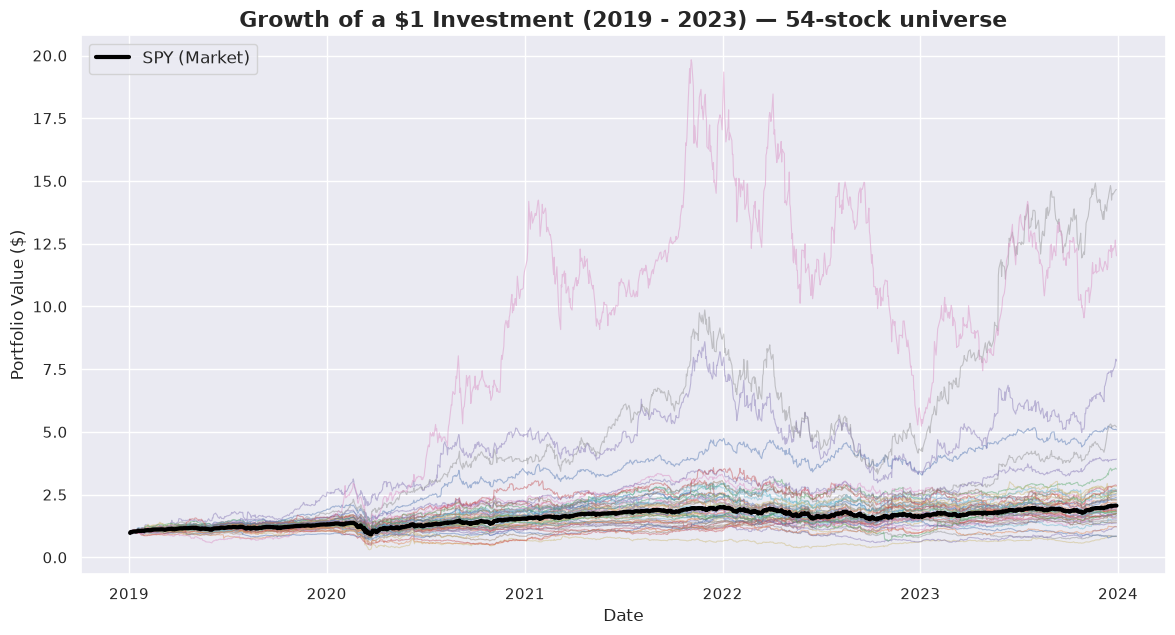

In [4]:
# Calculate cumulative growth
cumulative_growth = (1 + returns).cumprod()

# Plot growth: SPY bold/black, the 50+ stocks thin so the chart stays legible
plt.figure(figsize=(14, 7))
for col in cumulative_growth.columns:
    if col == "SPY":
        plt.plot(cumulative_growth.index, cumulative_growth[col],
                 label="SPY (Market)", linewidth=3, color="black", zorder=10)
    else:
        plt.plot(cumulative_growth.index, cumulative_growth[col],
                 linewidth=0.8, alpha=0.45)

plt.title(f"Growth of a $1 Investment (2019 - 2023) — {cumulative_growth.shape[1] - 1}-stock universe",
          fontsize=16, weight="bold")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend(fontsize=12, loc="upper left")
plt.show()


## 4. CAPM Regression (Alpha & Beta Estimation)

We run ordinary least squares (OLS) regressions of each stock's excess return against the market excess return (SPY). 

We assume an annualized risk-free rate of **4.0%** ($R_f = 0.04$). The daily risk-free rate is calculated as: $R_{f, \text{daily}} = \frac{R_f}{252}$.

In [5]:
# Define annual risk-free rate and daily conversion
rf_annual = 0.04
rf_daily = rf_annual / 252

# Calculate excess returns
excess_returns = returns.copy()
for col in excess_returns.columns:
    excess_returns[col] = excess_returns[col] - rf_daily

# Define market excess returns (independent variable)
X = excess_returns['SPY']
X_with_const = sm.add_constant(X)

# Regression container
results = {}

# Loop through stocks and fit OLS
# Use the tickers that actually returned data, not the requested list
stocks = [t for t in data.columns if t != 'SPY']
for stock in stocks:
    Y = excess_returns[stock]
    model = sm.OLS(Y, X_with_const).fit()
    results[stock] = {
        "alpha_daily": model.params['const'],
        "beta": model.params['SPY'],
        "r_squared": model.rsquared,
        "p_values": model.pvalues
    }
    print(f"=== Regression Summary: {stock} ===")
    print(f"Alpha (Daily): {model.params['const']:.6f}")
    print(f"Beta:          {model.params['SPY']:.4f}")
    print(f"R-Squared:     {model.rsquared:.4f}\n")

=== Regression Summary: AAPL ===
Alpha (Daily): 0.000718
Beta:          1.2352
R-Squared:     0.6473

=== Regression Summary: ABBV ===
Alpha (Daily): 0.000297
Beta:          0.5942
R-Squared:     0.2405

=== Regression Summary: ABT ===
Alpha (Daily): -0.000006
Beta:          0.8268
R-Squared:     0.4336

=== Regression Summary: ADBE ===
Alpha (Daily): 0.000241
Beta:          1.2837
R-Squared:     0.5358

=== Regression Summary: AMD ===
Alpha (Daily): 0.001228
Beta:          1.6212
R-Squared:     0.4019

=== Regression Summary: AMGN ===
Alpha (Daily): 0.000086
Beta:          0.6467
R-Squared:     0.2877

=== Regression Summary: AMZN ===
Alpha (Daily): 0.000079
Beta:          1.0879
R-Squared:     0.4206

=== Regression Summary: AVGO ===
Alpha (Daily): 0.000755
Beta:          1.3210
R-Squared:     0.5706

=== Regression Summary: BA ===
Alpha (Daily): -0.000556
Beta:          1.4910
R-Squared:     0.3855

=== Regression Summary: BAC ===
Alpha (Daily): -0.000196
Beta:          1.2395
R-Squ

## 5. Risk-Adjusted Ratios (Sharpe & Treynor)

We calculate:
1. **Annualized Volatility**: $\sigma_{\text{annual}} = \sigma_{\text{daily}} \times \sqrt{252}$
2. **Annualized Returns**: $R_{\text{annual}} = R_{\text{daily}} \times 252$
3. **Sharpe Ratio**: $\frac{R_{\text{annual}} - R_{f}}{\sigma_{\text{annual}}}$
4. **Treynor Ratio**: $\frac{R_{\text{annual}} - R_{f}}{\beta}$

In [6]:
summary_data = []

for stock in stocks:
    # Returns and volatility
    stock_returns = returns[stock]
    ann_return = stock_returns.mean() * 252
    ann_vol = stock_returns.std() * np.sqrt(252)
    
    # Alpha/Beta from regression
    beta = results[stock]["beta"]
    alpha_ann = results[stock]["alpha_daily"] * 252 # Annualized alpha
    
    # Ratios
    sharpe = (ann_return - rf_annual) / ann_vol if ann_vol > 0 else 0
    treynor = (ann_return - rf_annual) / beta if beta > 0 else 0
    
    summary_data.append({
        "Stock": stock,
        "Annualized Return": f"{ann_return*100:.2f}%",
        "Annualized Volatility": f"{ann_vol*100:.2f}%",
        "Beta (Systematic Risk)": round(beta, 2),
        "Annualized Alpha": f"{alpha_ann*100:.2f}%",
        "Sharpe Ratio": round(sharpe, 3),
        "Treynor Ratio": round(treynor, 3)
    })

# Add Market benchmark SPY
spy_returns = returns['SPY']
spy_ann_return = spy_returns.mean() * 252
spy_ann_vol = spy_returns.std() * np.sqrt(252)
spy_sharpe = (spy_ann_return - rf_annual) / spy_ann_vol

summary_data.append({
    "Stock": "SPY (Market)",
    "Annualized Return": f"{spy_ann_return*100:.2f}%",
    "Annualized Volatility": f"{spy_ann_vol*100:.2f}%",
    "Beta (Systematic Risk)": 1.0,
    "Annualized Alpha": "0.00%",
    "Sharpe Ratio": round(spy_sharpe, 3),
    "Treynor Ratio": round((spy_ann_return - rf_annual) / 1.0, 3)
})

df_summary = pd.DataFrame(summary_data).set_index("Stock")
df_summary

,Annualized Return,Annualized Volatility,Beta (Systematic Risk),Annualized Alpha,Sharpe Ratio,Treynor Ratio
Stock,,,,,,
AAPL,37.80%,32.23%,1.24,18.09%,1.049,0.274
ABBV,19.04%,25.44%,0.59,7.48%,0.591,0.253
ABT,14.37%,26.36%,0.83,-0.15%,0.393,0.125
ADBE,26.42%,36.82%,1.28,6.08%,0.609,0.175
AMD,55.56%,53.69%,1.62,30.93%,0.960,0.318
AMGN,14.39%,25.31%,0.65,2.16%,0.410,0.161
AMZN,19.84%,35.22%,1.09,2.00%,0.450,0.146
AVGO,39.84%,36.72%,1.32,19.04%,0.976,0.271
BA,8.95%,50.42%,1.49,-14.02%,0.098,0.033


## 6. Security Characteristic Line (SCL) Visualization

The Security Characteristic Line (SCL) plots the excess returns of a stock against the excess returns of the market. The slope is Beta and the intercept is Alpha.

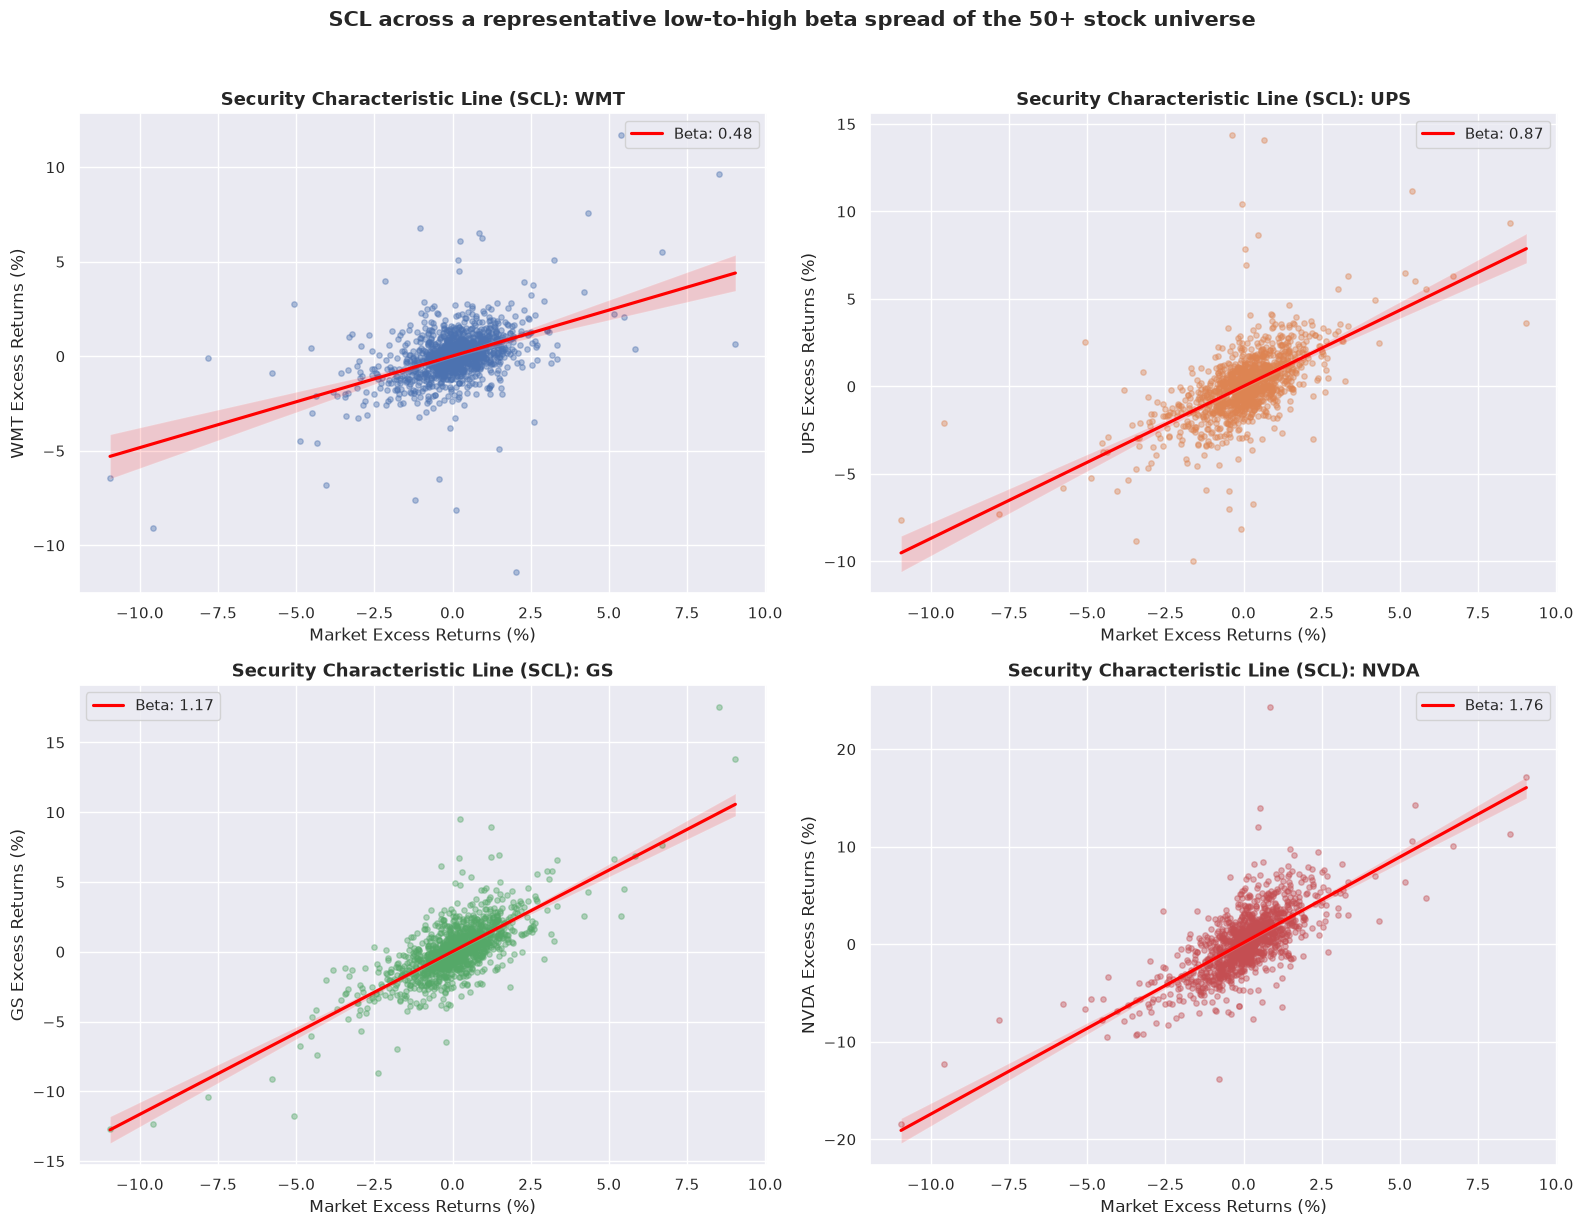

In [7]:
# With 50+ stocks an individual SCL per name is unreadable, so we plot a
# representative spread: the lowest-beta, two mid-beta, and highest-beta names.
ranked = sorted(stocks, key=lambda s: results[s]["beta"])
n = len(ranked)
featured = [ranked[0], ranked[n // 3], ranked[2 * n // 3], ranked[-1]]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, stock in enumerate(featured):
    sns.regplot(
        x=excess_returns["SPY"] * 100,  # in %
        y=excess_returns[stock] * 100,  # in %
        ax=axes[idx],
        color="C" + str(idx),
        scatter_kws={"alpha": 0.4, "s": 15},
        line_kws={"color": "red", "label": f"Beta: {results[stock]['beta']:.2f}"},
    )
    axes[idx].set_title(f"Security Characteristic Line (SCL): {stock}",
                        fontsize=13, weight="bold")
    axes[idx].set_xlabel("Market Excess Returns (%)")
    axes[idx].set_ylabel(f"{stock} Excess Returns (%)")
    axes[idx].legend(fontsize=11)

fig.suptitle("SCL across a representative low-to-high beta spread of the 50+ stock universe",
             fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 7. Monte Carlo Value at Risk (VaR)

We estimate the downside risk of an **equal-weight portfolio of the 50+ stocks**
using Monte Carlo simulation. Daily returns are modelled as draws from a
multivariate normal calibrated to the sample mean vector and covariance matrix,
then compounded over a 21-trading-day (~1 month) horizon.

From 10,000 simulated portfolio paths we report:
- **95% / 99% VaR** — the loss not exceeded with 95% / 99% confidence
- **95% CVaR (Expected Shortfall)** — the average loss in the worst 5% of paths


Monte Carlo VaR — 10,000 simulations, 21-day horizon
Equal-weight portfolio of 54 stocks, $1,000,000 initial investment

95% VaR : $83,291  (8.33% of portfolio)
99% VaR : $122,603  (12.26% of portfolio)
95% CVaR: $107,213  (10.72% of portfolio)


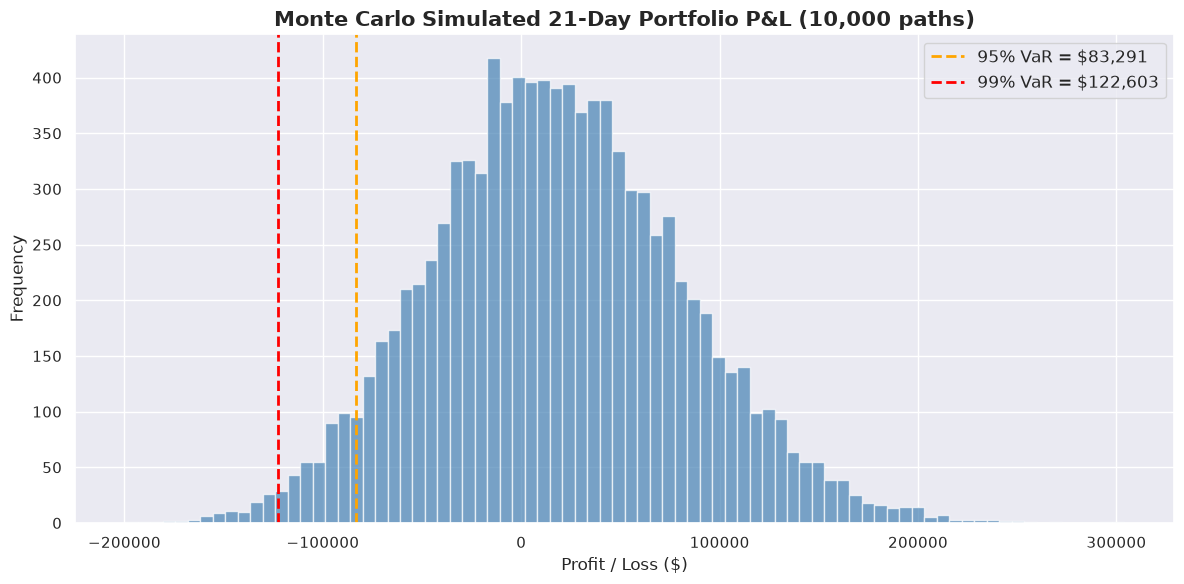

In [8]:
# Monte Carlo VaR for an equal-weight portfolio of the 50+ stock universe
np.random.seed(42)
N_SIMULATIONS = 10_000
HORIZON_DAYS = 21          # ~1 trading month
INITIAL_INVESTMENT = 1_000_000

port_stocks = [t for t in returns.columns if t != "SPY"]
weights = np.repeat(1.0 / len(port_stocks), len(port_stocks))

mu = returns[port_stocks].mean().values        # mean daily return vector
cov = returns[port_stocks].cov().values        # daily covariance matrix

# Draw (N_SIMULATIONS x HORIZON_DAYS) daily return vectors and compound them
draws = np.random.multivariate_normal(mu, cov, size=(N_SIMULATIONS, HORIZON_DAYS))
port_daily = draws @ weights                    # (N_SIMULATIONS, HORIZON_DAYS)
sim_horizon_returns = np.prod(1 + port_daily, axis=1) - 1

pnl = sim_horizon_returns * INITIAL_INVESTMENT
var_95 = -np.percentile(pnl, 5)
var_99 = -np.percentile(pnl, 1)
cvar_95 = -pnl[pnl <= np.percentile(pnl, 5)].mean()

print(f"Monte Carlo VaR — {N_SIMULATIONS:,} simulations, {HORIZON_DAYS}-day horizon")
print(f"Equal-weight portfolio of {len(port_stocks)} stocks, "
      f"${INITIAL_INVESTMENT:,.0f} initial investment\n")
print(f"95% VaR : ${var_95:,.0f}  ({var_95 / INITIAL_INVESTMENT * 100:.2f}% of portfolio)")
print(f"99% VaR : ${var_99:,.0f}  ({var_99 / INITIAL_INVESTMENT * 100:.2f}% of portfolio)")
print(f"95% CVaR: ${cvar_95:,.0f}  ({cvar_95 / INITIAL_INVESTMENT * 100:.2f}% of portfolio)")

plt.figure(figsize=(12, 6))
plt.hist(pnl, bins=80, color="steelblue", alpha=0.7, edgecolor="white")
plt.axvline(-var_95, color="orange", linestyle="--", linewidth=2,
            label=f"95% VaR = ${var_95:,.0f}")
plt.axvline(-var_99, color="red", linestyle="--", linewidth=2,
            label=f"99% VaR = ${var_99:,.0f}")
plt.title(f"Monte Carlo Simulated {HORIZON_DAYS}-Day Portfolio P&L "
          f"({N_SIMULATIONS:,} paths)", fontsize=15, weight="bold")
plt.xlabel("Profit / Loss ($)")
plt.ylabel("Frequency")
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()
